In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

In [2]:
housing=fetch_california_housing(as_frame=True)
df=housing.frame.copy()

print(df.head())
#Target_column
col='AveRooms'

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [3]:
#Outlier detection using IQR
def detect_outliers_iqr(data, feature, factor=1.5):
    q1=data[feature].quantile(0.25)
    q3=data[feature].quantile(0.75)
    iqr=q3-q1
    lb=q1-factor*iqr
    ub=q3+factor*iqr

    outliers=data[(data[feature] < lb) | (data[feature] > ub)]
    return lb, ub, outliers


In [4]:
#Outlier detection using z-score
def detect_outliers_zscore(data, feature, threshold=3.0):
    mean=data[feature].mean()
    std=data[feature].std()

    z_score=(data[feature]-mean)/std
    outliers=data[np.abs(data[feature] > threshold)]
    return mean - threshold * std, mean + threshold * std, outliers

In [5]:
lower_iqr, upper_iqr, iqr_outliers = detect_outliers_iqr(df, col)

if isinstance(iqr_outliers, (pd.DataFrame, pd.Series)):
    outlier_count = iqr_outliers.shape[0]
elif isinstance(iqr_outliers, (list, tuple)):
    outlier_count = len(iqr_outliers)
else:
    outlier_count = int(iqr_outliers)

print(f"[{col}] IQR Outlier Count: {outlier_count} out of {len(df)} rows")
# print(f"Bounds: Lower = {lower_iqr:.2f}, Upper = {upper_iqr:.2f}")

# 4. Preview Top Outliers (Optional)
if outlier_count > 0 and isinstance(iqr_outliers, (pd.DataFrame, pd.Series)):
    print("\nSample Outlier Rows:")
    print(iqr_outliers.head())

[AveRooms] IQR Outlier Count: 511 out of 20640 rows

Sample Outlier Rows:
      MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
73    0.4999      46.0  1.714286   0.571429        18.0  2.571429     37.81   
155   8.8793      52.0  8.972868   1.131783       861.0  3.337209     37.81   
511  13.4990      42.0  8.928358   1.000000      1018.0  3.038806     37.82   
512  12.2138      52.0  9.210227   1.039773      1001.0  2.843750     37.82   
514  12.3804      52.0  9.122715   1.033943      1192.0  3.112272     37.82   

     Longitude  MedHouseVal  
73     -122.29      0.67500  
155    -122.23      4.10300  
511    -122.22      5.00001  
512    -122.23      5.00001  
514    -122.23      5.00001  


In [7]:
#Handling_Outliers
#A. Capping
df_capped=df.copy()
df_capped[col]=np.clip(df_capped[col], lower_iqr, upper_iqr)

#B.Imputation
df_imputed=df.copy()
mask_outliers=(df_imputed[col] < lower_iqr) | (df_imputed[col] > upper_iqr)
df_imputed.loc[mask_outliers, col]=np.nan

median=df_imputed[col].median()
df_imputed[col].fillna(median, inplace=True)

C:\Users\msi\AppData\Local\Temp\ipykernel_24820\483959571.py:12: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df_imputed[col].fillna(median, inplace=True)


0        6.984127
1        6.238137
2        8.288136
3        5.817352
4        6.281853
           ...   
20635    5.045455
20636    6.114035
20637    5.205543
20638    5.329513
20639    5.254717
Name: AveRooms, Length: 20640, dtype: float64

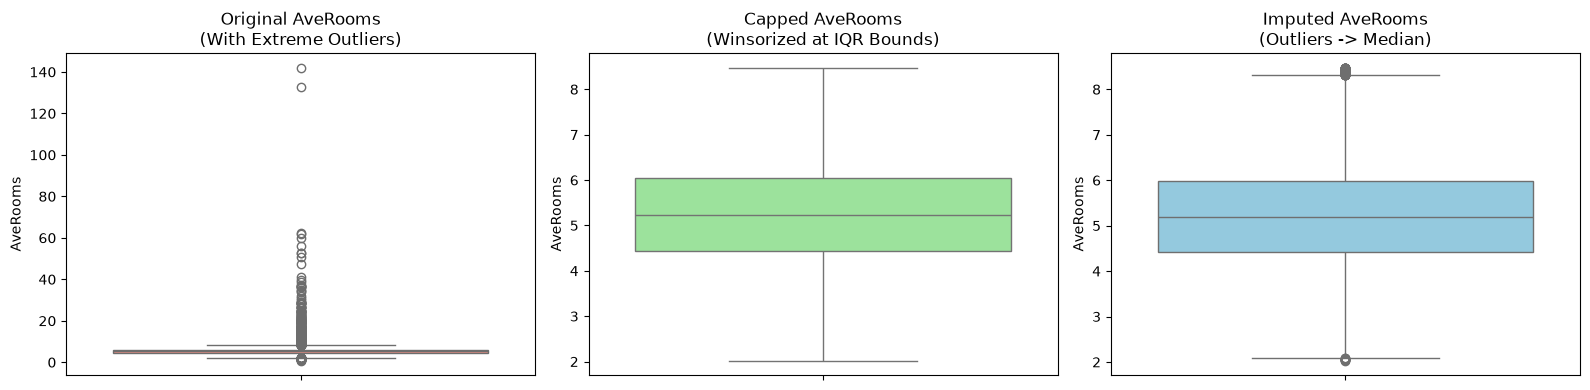

In [8]:
#Visual_plot
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(y=df[col], ax=axes[0], color='salmon')
axes[0].set_title(f"Original {col}\n(With Extreme Outliers)")

sns.boxplot(y=df_capped[col], ax=axes[1], color='lightgreen')
axes[1].set_title(f"Capped {col}\n(Winsorized at IQR Bounds)")

sns.boxplot(y=df_imputed[col], ax=axes[2], color='skyblue')
axes[2].set_title(f"Imputed {col}\n(Outliers -> Median)")

plt.tight_layout()
plt.show()